# 02 — Feature engineering

**Goal:** turn the churn patterns from notebook 01 into explicit, explainable model features.

**Leakage rules used throughout:**
- No feature uses the target column.
- Thresholds are *fixed business values* (e.g. $70), never statistics computed from the full dataset.
- Anything that must be *fitted* (scaling, one-hot encoding, imputation) happens inside the scikit-learn `Pipeline`, which is fitted on training data only.

In [1]:
import sys
from pathlib import Path

# Make the src package importable when running from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 40)
FIG = PROJECT_ROOT / "reports" / "figures"

In [2]:
from src.data_cleaning import load_raw_data, clean_customers
from src.feature_engineering import add_features, FEATURE_RATIONALE

clean = clean_customers(load_raw_data())
features = add_features(clean)

new_cols = [c for c in features.columns if c not in clean.columns]
print(f"{len(new_cols)} engineered features added:")
new_cols

12 engineered features added:


['tenure_group',
 'is_month_to_month',
 'has_auto_payment',
 'num_services',
 'is_paperless',
 'avg_charges_per_month',
 'high_monthly_charge',
 'has_internet',
 'has_fiber',
 'streaming_bundle',
 'support_bundle',
 'spend_group']

## Why each feature might relate to churn

In [3]:
pd.DataFrame(FEATURE_RATIONALE.items(), columns=["feature", "why it may relate to churn"])

,feature,why it may relate to churn
0,tenure_group,Churn risk falls sharply as customers age; gro...
1,is_month_to_month,Month-to-month customers can leave at any time...
2,has_auto_payment,Automatic payments signal commitment and remov...
3,num_services,Customers with more subscribed services are mo...
4,is_paperless,Paperless-billing customers skew digital-first...
5,avg_charges_per_month,Lifetime spend per month of tenure; differs fr...
6,high_monthly_charge,"Bills above $70/month create price pressure, e..."
7,has_internet,Internet subscribers face more competition and...
8,has_fiber,"Fiber customers pay the most and, in this data..."
9,streaming_bundle,Subscribing to both streaming products indicat...


## Do the engineered flags actually separate churners?

For every binary flag, compare the churn rate when the flag is 0 vs 1.

In [4]:
from src.feature_engineering import BINARY_FEATURES

rows = []
for flag in BINARY_FEATURES:
    grp = features.groupby(flag)["churn"].mean()
    rows.append({"feature": flag,
                 "churn rate (flag=0)": round(grp.get(0, float("nan")), 3),
                 "churn rate (flag=1)": round(grp.get(1, float("nan")), 3)})
pd.DataFrame(rows).sort_values("churn rate (flag=1)", ascending=False)

,feature,churn rate (flag=0),churn rate (flag=1)
0,is_month_to_month,0.068,0.427
5,has_fiber,0.145,0.419
3,high_monthly_charge,0.174,0.354
2,is_paperless,0.163,0.336
4,has_internet,0.074,0.318
6,streaming_bundle,0.254,0.294
1,has_auto_payment,0.347,0.160
7,support_bundle,0.298,0.090


In [5]:
# Grouped features
for col in ["tenure_group", "spend_group"]:
    print(features.groupby(col)["churn"].agg(["mean", "count"]).round(3), "\n")

               mean  count
tenure_group              
0-12m         0.474   2186
13-24m        0.287   1024
25-48m        0.204   1594
49-72m        0.095   2239 

              mean  count
spend_group              
high         0.354   3583
low          0.109   1735
medium       0.239   1725 



`is_month_to_month`, `has_fiber` and `high_monthly_charge` all mark segments churning at ~2x the base rate, while `has_auto_payment` and `support_bundle` mark clearly safer segments — exactly the separation a model can exploit.

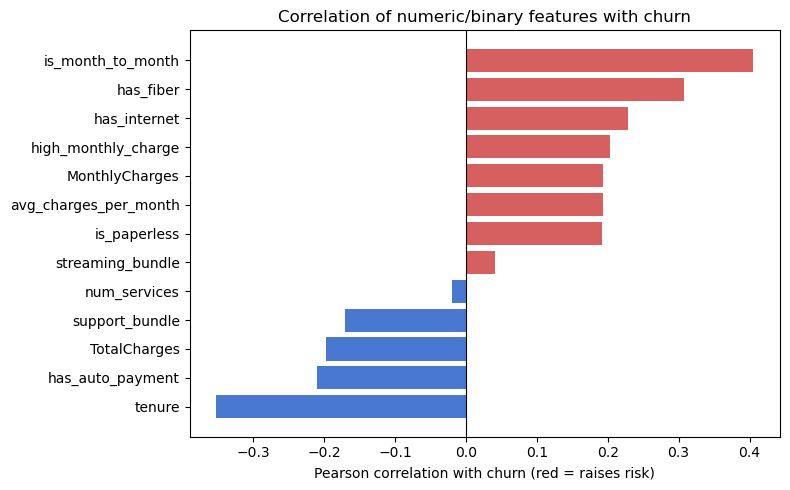

In [6]:
from src.feature_engineering import NUMERIC_FEATURES

corr = (features[NUMERIC_FEATURES + BINARY_FEATURES + ["churn"]]
        .corr()["churn"].drop("churn").sort_values())

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#D65F5F" if v > 0 else "#4878CF" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation of numeric/binary features with churn")
ax.set_xlabel("Pearson correlation with churn (red = raises risk)")
plt.tight_layout()
plt.show()

## Feature roles for modelling

The lists below (defined once in `src/feature_engineering.py`) are used by the training pipeline. Note what's **excluded**: `customerID` (identifier) and `churn` (target) can never leak into the features.

In [7]:
from src.feature_engineering import MODEL_FEATURES, CATEGORICAL_FEATURES

print(f"numeric ({len(NUMERIC_FEATURES)}):", NUMERIC_FEATURES)
print(f"\nbinary ({len(BINARY_FEATURES)}):", BINARY_FEATURES)
print(f"\ncategorical ({len(CATEGORICAL_FEATURES)}):", CATEGORICAL_FEATURES)
print(f"\ntotal model features: {len(MODEL_FEATURES)}")

numeric (5): ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_charges_per_month']

binary (8): ['is_month_to_month', 'has_auto_payment', 'is_paperless', 'high_monthly_charge', 'has_internet', 'has_fiber', 'streaming_bundle', 'support_bundle']

categorical (18): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group', 'spend_group']

total model features: 31


## Takeaway

We now have 33 columns per customer: the cleaned raw attributes plus 12 engineered features, each with a documented business rationale. The table is stored in SQL (`customer_features`) by `python main.py setup`, and `03_model_evaluation.ipynb` looks at what the models learned from it.